In [ ]:
!pip -q install pandas numpy scikit-learn requests matplotlib seaborn joblib openpyxl

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# DATASET
**Link Dataset yang digunakan:** _(Data harga cabai dari : BPS & data iklim cuaca dari API open-meteo.com, Dataset Harga Harian Komoditas Cabai di Jawa Barat : https://drive.google.com/file/d/1-k-uhAXAR0O61s6T1V6fO_fg-NmXHMdx/view?usp=sharing)_


  

# Challenge 1 - Data Exploration (Pandas)
Tujuan: Memahami struktur dataset, mendeteksi missing values, dan menampilkan insight awal.

### Soal 1.1: Muat dataset

In [ ]:
file_path = '/content/drive/MyDrive/Perempuan Inovasi 2026/Bootcam/Materi/Life Session AI Fundamental/Tugas/Collab/dataset_cabai/harga_cabai_jabar_2020-2026.csv'
df = pd.read_csv(file_path)
df.head()

,tanggal,besar_harga,keriting_harga,rawit_hijau_harga,rawit_merah_harga,suhu_rata,curah_hujan,kelembapan,radiasi_matahari,evapotranspirasi
0,2020-01-01,29750.0,22950.0,13350.0,13350.0,22.0,15.2,89,5.60,1.32
1,2020-01-02,29750.0,22950.0,13350.0,13350.0,21.9,6.4,86,12.11,2.41
2,2020-01-03,29750.0,22950.0,13350.0,13350.0,23.2,0.0,80,17.24,3.63
3,2020-01-04,29750.0,22950.0,13350.0,13350.0,23.2,1.2,84,17.33,3.49
4,2020-01-05,29750.0,22950.0,13350.0,13350.0,23.1,4.3,84,15.04,3.08


### Soal 1.2: Informasi umum dataset

In [ ]:
# Soal 1.2: Informasi umum dataset
print('=== Dataset Info ===')
df.info()

print('\n=== Dataset Describe ===')
print(df.describe())

print('\n=== Missing Values ===')
print(df.isnull().sum())

print('\n=== Duplicated Rows ===')
print(f'Total: {df.duplicated().sum()}')

print('\n=== Jumlah Row ===')
print(len(df))

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2465 entries, 0 to 2464
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   tanggal            2465 non-null   object 
 1   besar_harga        2465 non-null   float64
 2   keriting_harga     2465 non-null   float64
 3   rawit_hijau_harga  2465 non-null   float64
 4   rawit_merah_harga  2465 non-null   float64
 5   suhu_rata          2465 non-null   float64
 6   curah_hujan        2465 non-null   float64
 7   kelembapan         2465 non-null   int64  
 8   radiasi_matahari   2465 non-null   float64
 9   evapotranspirasi   2465 non-null   float64
dtypes: float64(8), int64(1), object(1)
memory usage: 192.7+ KB

=== Dataset Describe ===
        besar_harga  keriting_harga  rawit_hijau_harga  rawit_merah_harga  \
count   2465.000000     2465.000000        2465.000000        2465.000000   
mean   38446.267748    27250.385396       24417.3427

**Challenge 1:**

**1. Karakteristik Data**:

Ada 2.465 row dengan 10 Columns

1.   tanggal
2.   besar_harga (mewakili harga cabai merah besar)
3.   keriting_harga (mewakili harga cabai merah keriting)
4.   rawit_hijau_harga (mewakili harga cabai rawit hijau)
5.   rawit_merah_harga (mewakili harga cabai rawit merah)
6.   suhu_rata (mewakili suhu rata-rata harian di jawa barat)
7.   curah_hujan
8.   kelembapan
9.   radiasi_matahari
10.  evapotranspirasi (jumlah air yang hilang ke atmosver dari permukaan tanah)


**2. Data Quality**: Tidak ada Missing Values dan duplicate row



#### Mendeteksi outlier menggunakan IQR

In [ ]:
hasil_outlier = []

# Mendefinisikan fitur_numerik secara otomatis dari kolom bertipe angka (kecuali tanggal)
fitur_numerik = df.select_dtypes(include=[np.number]).columns.tolist()

for kolom in fitur_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)

    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    mask_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    )

    hasil_outlier.append({
        "fitur": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "batas_bawah": batas_bawah,
        "batas_atas": batas_atas,
        "jumlah_outlier": int(mask_outlier.sum()),
        "persentase_outlier": mask_outlier.mean() * 100
    })

tabel_outlier = pd.DataFrame(hasil_outlier)

display(
    tabel_outlier.sort_values(
        "jumlah_outlier", ascending=False
    ).round(3)
)

,fitur,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persentase_outlier
5,curah_hujan,0.40,7.30,6.90,-9.950,17.650,223,9.047
6,kelembapan,76.00,85.00,9.00,62.500,98.500,94,3.813
4,suhu_rata,22.50,23.50,1.00,21.000,25.000,62,2.515
1,keriting_harga,18950.00,33700.00,14750.00,-3175.000,55825.000,31,1.258
3,rawit_merah_harga,16150.00,31150.00,15000.00,-6350.000,53650.000,30,1.217
2,rawit_hijau_harga,16150.00,31150.00,15000.00,-6350.000,53650.000,30,1.217
7,radiasi_matahari,16.05,21.57,5.52,7.770,29.850,26,1.055
8,evapotranspirasi,3.19,4.38,1.19,1.405,6.165,17,0.690
0,besar_harga,24100.00,50800.00,26700.00,-15950.000,90850.000,0,0.000


**3. Distribusi Fitur**:

Outlier terbanyak pada curah_hujan 9,047%, kemungkinan mencerminkan kejadian hujan ekstrem

Harga Cabai merah besar (column: besar_harga) tidak ditemukan Outlier berdasarkan batas IQR



In [ ]:
#Melihat tanggal terjadinya Outlier
kolom_uji = "curah_hujan"  # Ganti dengan fitur yang ingin diperiksa

Q1 = df[kolom_uji].quantile(0.25)
Q3 = df[kolom_uji].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = df[
    (df[kolom_uji] < batas_bawah) |
    (df[kolom_uji] > batas_atas)
].sort_values(kolom_uji, ascending=False)

display(outlier[["tanggal", kolom_uji]].head(20))

,tanggal,curah_hujan
455,2021-03-31,91.3
293,2020-10-20,77.4
1219,2023-05-04,67.6
43,2020-02-13,65.8
1467,2024-01-07,58.2
1604,2024-05-23,57.8
336,2020-12-02,55.4
8,2020-01-09,53.5
1968,2025-05-22,50.8
86,2020-03-27,50.8


#### Analisis Korelasi antar fitur

In [ ]:
korelasi = df[fitur_numerik].corr(method="pearson")

display(korelasi.round(3))

,besar_harga,keriting_harga,rawit_hijau_harga,rawit_merah_harga,suhu_rata,curah_hujan,kelembapan,radiasi_matahari,evapotranspirasi
besar_harga,1.000,0.689,0.874,0.874,0.027,0.027,0.076,0.003,-0.023
keriting_harga,0.689,1.000,0.669,0.669,-0.020,0.066,0.108,-0.016,-0.044
rawit_hijau_harga,0.874,0.669,1.000,1.000,0.009,-0.031,0.005,0.018,0.002
rawit_merah_harga,0.874,0.669,1.000,1.000,0.009,-0.031,0.005,0.018,0.002
suhu_rata,0.027,-0.020,0.009,0.009,1.000,-0.226,-0.547,0.508,0.566
curah_hujan,0.027,0.066,-0.031,-0.031,-0.226,1.000,0.460,-0.444,-0.457
kelembapan,0.076,0.108,0.005,0.005,-0.547,0.460,1.000,-0.702,-0.807
radiasi_matahari,0.003,-0.016,0.018,0.018,0.508,-0.444,-0.702,1.000,0.979
evapotranspirasi,-0.023,-0.044,0.002,0.002,0.566,-0.457,-0.807,0.979,1.000


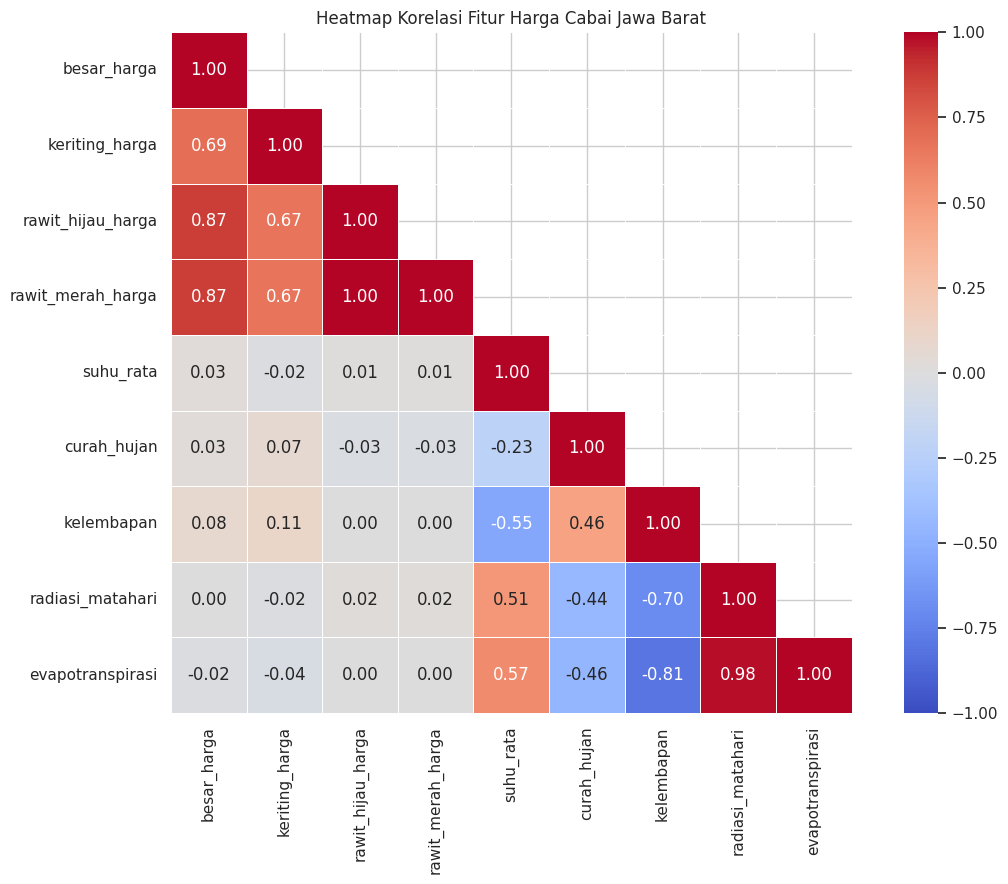

In [ ]:
plt.figure(figsize=(12, 9))

mask = np.triu(
    np.ones_like(korelasi, dtype=bool),
    k=1
)

sns.heatmap(
    korelasi,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Heatmap Korelasi Fitur Harga Cabai Jawa Barat")
plt.tight_layout()
plt.show()

**4. Korelasi**:

radiasi_matahari dan evapotranspirasi (0.98): Ini adalah korelasi tertinggi antar-fitur cuaca. Nilai 0.98 menunjukkan korelasi positif. Semakin tinggi radiasi atau paparan sinar matahari, maka proses penguapan air (evapotranspirasi) di lahan cabai akan meningkat secara drastis.

rawit_hijau_harga dan rawit_merah_harga (1.00): Korelasi bernilai 1.00 menunjukkan bahwa pergerakan harga cabai rawit hijau dan cabai rawit merah berbanding lurus

kelembapan dan radiasi_matahari (-0.70): Menunjukkan bahwa saat intensitas sinar matahari tinggi, kelembapan udara di area tersebut akan menurun signifikan

### Soal 1.3: Visualisasi data (minimal 2 grafik)

/tmp/ipykernel_8728/2698997231.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(['Rp {:,.0f}'.format(x) for x in current_values])


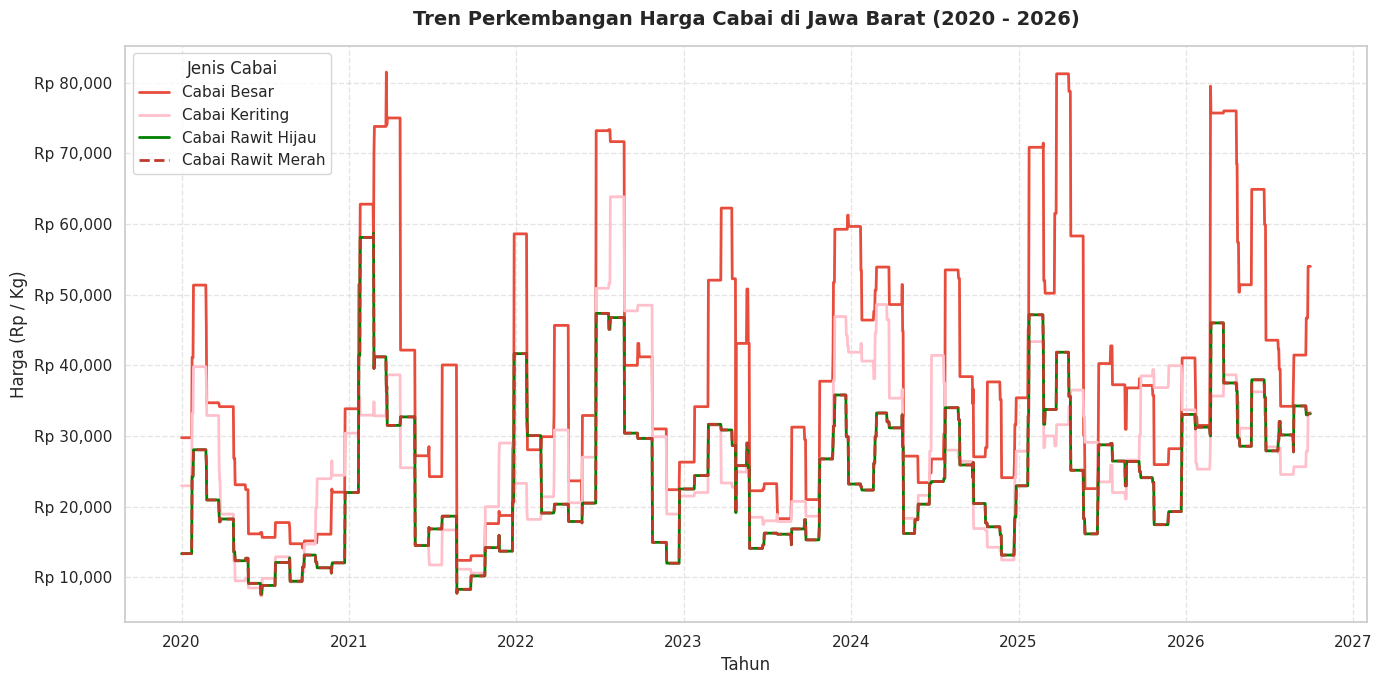

In [ ]:
# 1. Pastikan kolom 'tanggal' bertipe datetime agar urutan waktunya benar
df['tanggal'] = pd.to_datetime(df['tanggal'])

# 2. Mengurutkan data berdasarkan tanggal dari yang paling lampau
df = df.sort_values('tanggal')

# 3. Mengatur gaya tampilan grafik (style) menggunakan seaborn
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# 4. Memplot grafik garis untuk masing-masing jenis cabai
plt.plot(df['tanggal'], df['besar_harga'], label='Cabai Besar', color='#E74C3C', linewidth=2)
plt.plot(df['tanggal'], df['keriting_harga'], label='Cabai Keriting', color='#FFC0CB', linewidth=2)
plt.plot(df['tanggal'], df['rawit_hijau_harga'], label='Cabai Rawit Hijau', color='#008000', linewidth=2)
plt.plot(df['tanggal'], df['rawit_merah_harga'], label='Cabai Rawit Merah', color='#C0392B', linewidth=2, linestyle='--')

# 5. Kustomisasi elemen grafik (Judul, Label, dan Legend)
plt.title('Tren Perkembangan Harga Cabai di Jawa Barat (2020 - 2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga (Rp / Kg)', fontsize=12)

# Mengatur format mata uang rupiah pada sumbu Y agar lebih rapi
current_values = plt.gca().get_yticks()
plt.gca().set_yticklabels(['Rp {:,.0f}'.format(x) for x in current_values])

plt.legend(title="Jenis Cabai", fontsize=11, title_fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

# 6. Menampilkan grafik
plt.tight_layout()
plt.show()


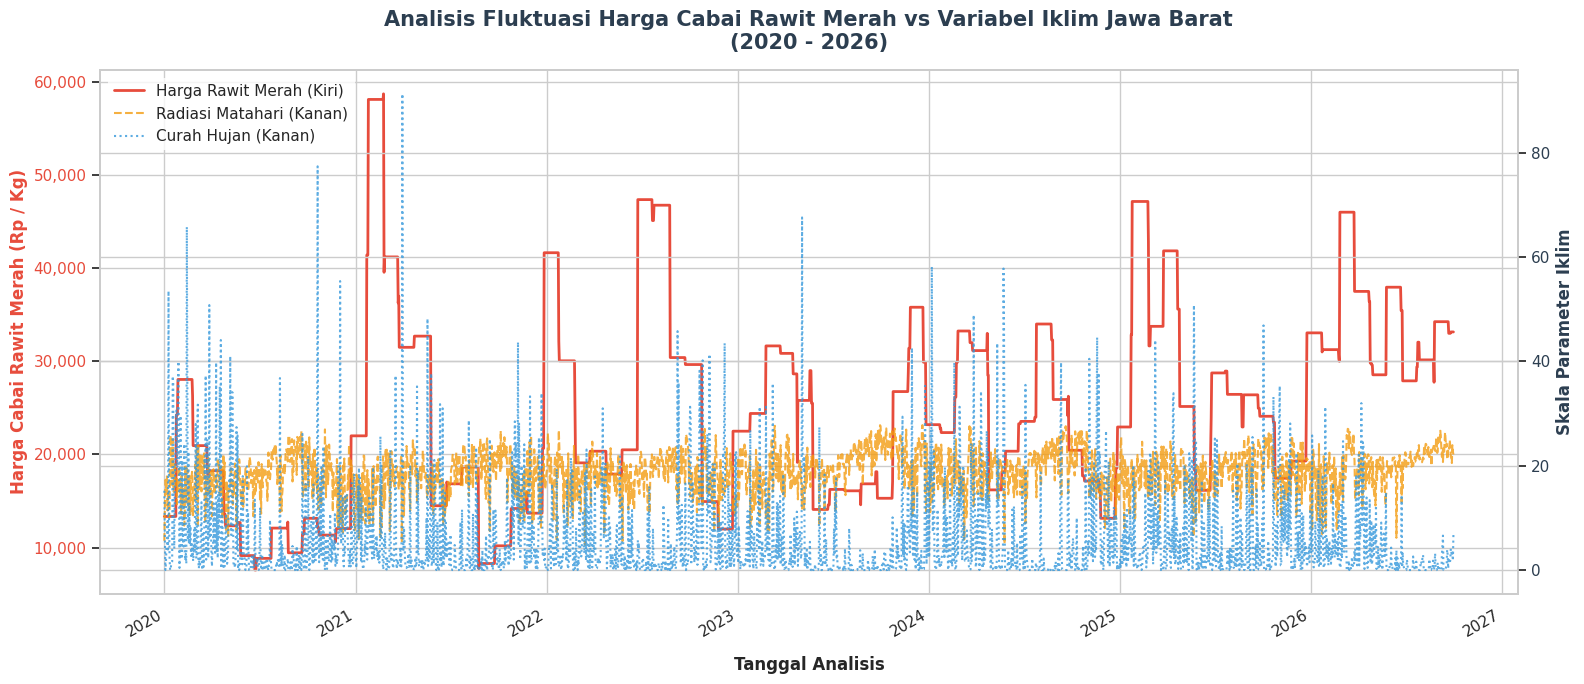

In [ ]:

# Menggunakan dataset yang sudah bersih
df['tanggal'] = pd.to_datetime(df['tanggal'])
df_plot = df.sort_values(by='tanggal').reset_index(drop=True)

# 2. Mengatur gaya visualisasi menggunakan Seaborn
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(16, 7))

# ==========================================
# PLOT 1: Tren Harga Cabai Rawit Merah (Sumbu Y Kiri)
# ==========================================
color_harga = '#E74C3C' # Warna merah cabai
ax1.set_xlabel('Tanggal Analisis', fontsize=12, fontweight='bold', labelpad=12)
ax1.set_ylabel('Harga Cabai Rawit Merah (Rp / Kg)', color=color_harga, fontsize=12, fontweight='bold')

# Plot garis harga cabai
line1 = ax1.plot(df_plot['tanggal'], df_plot['rawit_merah_harga'],
                 color=color_harga, linewidth=2, label='Harga Rawit Merah (Kiri)')
ax1.tick_params(axis='y', labelcolor=color_harga)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# ==========================================
# PLOT 2: Variabel Iklim Utama (Sumbu Y Kanan)
# ==========================================
# Membuat sumbu Y kedua yang berbagi sumbu X yang sama
ax2 = ax1.twinx()

color_radiasi = '#F39C12' # Warna oren matahari
color_hujan = '#3498DB'    # Warna biru penguapan

ax2.set_ylabel('Skala Parameter Iklim', color='#2C3E50', fontsize=12, fontweight='bold')

# Plot garis Radiasi Matahari
line2 = ax2.plot(df_plot['tanggal'], df_plot['radiasi_matahari'],
                 color=color_radiasi, linewidth=1.5, linestyle='--', alpha=0.8, label='Radiasi Matahari (Kanan)')

# Plot garis Curah Hujan (Menggantikan Evapotranspirasi)
line3 = ax2.plot(df_plot['tanggal'], df_plot['curah_hujan'],
                 color=color_hujan, linewidth=1.5, linestyle=':', alpha=0.8, label='Curah Hujan (Kanan)')
ax2.tick_params(axis='y', labelcolor='#2C3E50')

# ==========================================
# PENGATURAN LEGENDA & ESTETIKA GRAFIK
# ==========================================
# Menggabungkan semua legenda dari ax1 dan ax2 agar bersatu
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11, frameon=True, facecolor='white', edgecolor='none')

plt.title('Analisis Fluktuasi Harga Cabai Rawit Merah vs Variabel Iklim Jawa Barat\n(2020 - 2026)',
          fontsize=15, fontweight='bold', pad=15, color='#2C3E50')

# Memutar format tanggal pada sumbu X agar tidak saling bertumpuk
fig.autofmt_xdate(rotation=30)

plt.tight_layout()

# Menyimpan grafik sebagai file gambar PNG beresolusi tinggi untuk dokumen laporan Anda
plt.savefig('visualisasi_cuaca_cabai_jabar.png', dpi=300)
plt.show()


# Challenge 2 - Machine Learning (Scikit-learn)

## Feature Engineering

In [ ]:
len(df)

2465

In [ ]:
# Data Preparation & Feature Engineering (VERSI PERBAIKAN)

# 1. Pastikan urutan kronologis berdasarkan tanggal
df['tanggal'] = pd.to_datetime(df['tanggal'])
df = df.sort_values(by='tanggal').reset_index(drop=True)

# 2. Membuat Fitur Ekstraksi Waktu (Menangkap Pola Musiman)
df['bulan'] = df['tanggal'].dt.month
df['hari_ke_minggu'] = df['tanggal'].dt.dayofweek

# 3. DEFINISIKAN TARGET (Memprediksi harga 1 hari ke depan)
# Pilih salah satu komoditas sebagai target utama, misal: cabai_rawit_merah
target_komoditas = 'rawit_merah_harga'
df['target_harga_besok'] = df[target_komoditas].shift(-1)

# 4. Bersihkan baris terakhir yang kosong akibat pergeseran target (shift -1)
df_clean = df.dropna().reset_index(drop=True)

print(f"Dataset berhasil diproses! Ukuran data sekarang: {df_clean.shape}")



Dataset berhasil diproses! Ukuran data sekarang: (2464, 13)


### Soal 2.1: Definisikan fitur (X) dan target (y)

In [ ]:
dataset_copy = df_clean.copy()
df = dataset_copy
# Tentukan nama kolom target
TARGET = 'target_harga_besok'

X = df.drop(columns=[TARGET, 'tanggal'])
y = df[TARGET]

print('=== Fitur (X) ===')
print(list(X.columns))

print('\n=== Target (y) ===')
print(f'Nama target: {TARGET}')
print(f'Tipe data: {y.dtype}')
print(f'Jumlah nilai unik: {y.nunique()}')

print('\n=== Distribusi / nilai target ===')
print(y.value_counts(dropna=False).head(20))

PROBLEM_TYPE = 'Regression'

print(f'\nJenis masalah: {PROBLEM_TYPE}')

=== Fitur (X) ===
['besar_harga', 'keriting_harga', 'rawit_hijau_harga', 'rawit_merah_harga', 'suhu_rata', 'curah_hujan', 'kelembapan', 'radiasi_matahari', 'evapotranspirasi', 'bulan', 'hari_ke_minggu']

=== Target (y) ===
Nama target: target_harga_besok
Tipe data: float64
Jumlah nilai unik: 148

=== Distribusi / nilai target ===
target_harga_besok
16850.0    56
20350.0    56
13150.0    53
22500.0    33
32700.0    32
29650.0    32
18650.0    32
10200.0    31
11350.0    31
31650.0    31
14950.0    31
46750.0    31
47150.0    31
12100.0    31
17450.0    31
31250.0    31
14200.0    30
8300.0     30
20500.0    30
16100.0    30
Name: count, dtype: int64

Jenis masalah: Regression


In [ ]:
print(f"\nJumlah sampel data yang siap dilatih: {X.shape[0]} baris")
print(f"Fitur yang digunakan untuk memprediksi: {list(X.columns)}")


Jumlah sampel data yang siap dilatih: 2464 baris
Fitur yang digunakan untuk memprediksi: ['besar_harga', 'keriting_harga', 'rawit_hijau_harga', 'rawit_merah_harga', 'suhu_rata', 'curah_hujan', 'kelembapan', 'radiasi_matahari', 'evapotranspirasi', 'bulan', 'hari_ke_minggu']


### Soal 2.2: Split data train/test

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Membagi data menjadi Train (80%) dan Test Set (20%)
# Catatan: shuffle=False digunakan karena data memiliki urutan waktu (time-series)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)



### Soal 2.3: Latih model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Membagi data menjadi Train (80%) dan Test Set (20%)
# Catatan: shuffle=False digunakan karena data memiliki urutan waktu (time-series)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 2. Inisialisasi ketiga model rekomendasi
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=1082026),
    "HistGradientBoosting Regressor": HistGradientBoostingRegressor(random_state=1082026)
}

# 3. Melatih model dan mengevaluasi hasilnya
performa_model = {}

for name, model in models.items():
    # Melatih model
    model.fit(X_train, y_train)

    # Melakukan prediksi pada data pengujian
    y_pred = model.predict(X_test)

    # Menghitung metrik evaluasi
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Menyimpan hasil evaluasi
    performa_model[name] = {"MAE": mae, "RMSE": rmse, "R2 Score": r2}



### Soal 2.4: Evaluasi model

In [ ]:
df_performa = pd.DataFrame(performa_model).T
print("=== PERBANDINGAN PERFORMA MODEL ===")
print(df_performa.to_string())

=== PERBANDINGAN PERFORMA MODEL ===
                                        MAE         RMSE  R2 Score
Linear Regression (Baseline)     395.832627  1302.881596  0.969119
Random Forest Regressor         2133.468560  2810.876163  0.856262
HistGradientBoosting Regressor  1756.534173  2335.267781  0.900789


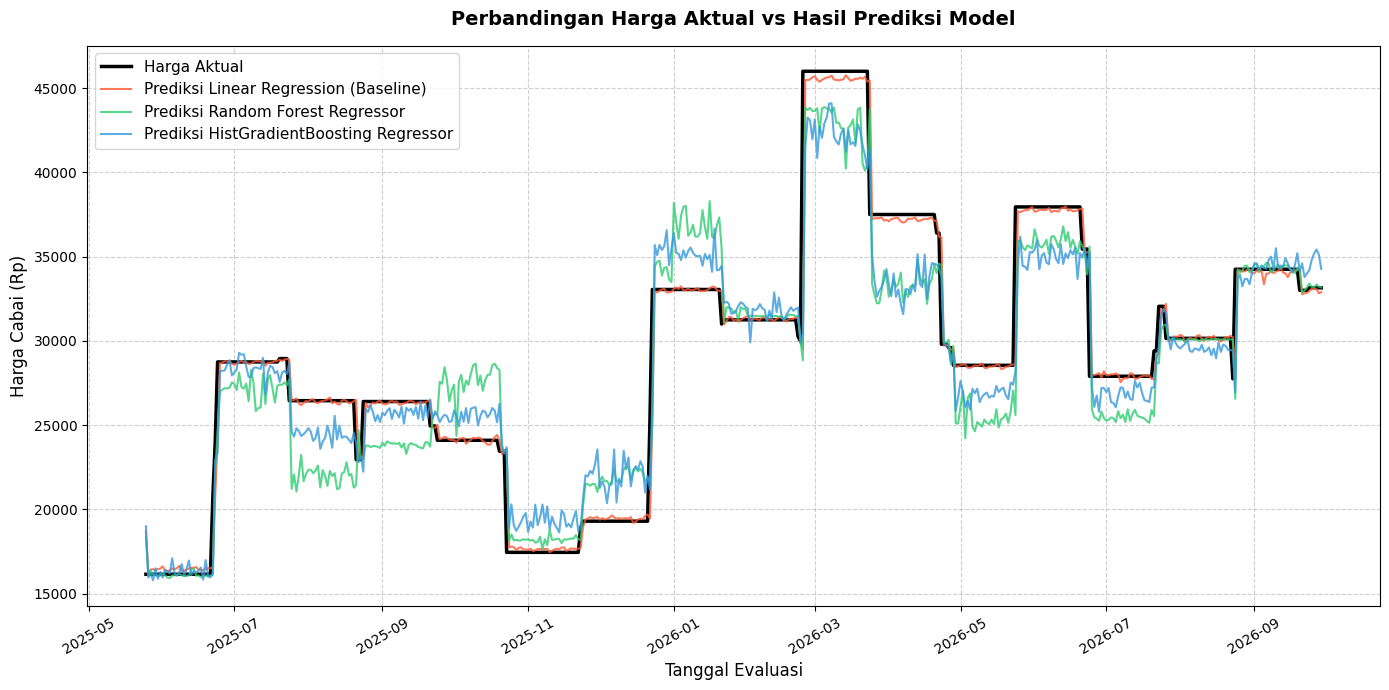

In [ ]:
# 1. Mengambil tanggal yang sesuai dengan data pengujian (Test Set)
# Karena kita menggunakan shuffle=False, indeks X_test bersesuaian dengan indeks tanggal asli
tanggal_test = df.loc[X_test.index, 'tanggal']

# 2. Mengatur ukuran kanvas grafik
plt.figure(figsize=(14, 7))

# 3. Memplot harga aktual
plt.plot(tanggal_test, y_test.values, label='Harga Aktual', color='black', linewidth=2.5, linestyle='-')

# 4. Memplot hasil prediksi dari masing-masing model
warna_model = {
    "Linear Regression (Baseline)": '#FF5733',       # Jingga
    "Random Forest Regressor": '#2ECC71',            # Hijau
    "HistGradientBoosting Regressor": '#3498DB'       # Biru
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    plt.plot(tanggal_test, y_pred, label=f'Prediksi {name}', color=warna_model[name], linewidth=1.5, alpha=0.8)

# 5. Kustomisasi tampilan grafik
plt.title('Perbandingan Harga Aktual vs Hasil Prediksi Model', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tanggal Evaluasi', fontsize=12)
plt.ylabel('Harga Cabai (Rp)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=30)
plt.legend(fontsize=11, loc='upper left')

# Menampilkan grafik secara rapi
plt.tight_layout()
plt.show()


### Overfitting / Underfitting

Bandingkan performa pada data training dan testing.

Perhatikan:
- Apakah performa training jauh lebih baik daripada testing?

Pada Random Forest dan HistGradientBoosting mengalami penurunan performa pada data testing.
Random Forest mengalami penurunan performa yang paling drastis dengan R2 hanya 0.565


- Apakah model terlalu sederhana sehingga performanya rendah pada keduanya?

Tidak bisa disimpulkan bahwa model terlalu sederhana, karena performanya pada salah satu atau kedua matriks pengujian tetap tinggi. Rendahnya performa Random Forest bukan karena modelnya terlalu sederhana, melainkan karena model pohon kesulitan melakukan ekstrapolasi tren waktu tanpa adanya fitur bantuan seperti lag atau moving average.

- Apakah terdapat indikasi overfitting atau underfitting?

Terjadi indikasi Overfitting yang kuat pada Random Forest Regressor sebelum saya menambahkan variabel iklim dan cuaca.
Random Forest sering kali "tertinggal" di bawah atau meleset jauh dari garis hitam (Harga Aktual) ketika harga sedang melonjak atau stabil di atas.

Namun, begitu data iklim/cuaca dimasukkan, model pohon mendapatkan "jangkar" informasi baru yang bersifat non-linear. Variabel cuaca memberikan dimensi konteks alamiah yang membantu model pohon memahami kenapa harga berubah, sehingga mampu memangkas nilai error (MAE) Random Forest dari Rp3.875 turun drastis menjadi hanya Rp2.133.



#### Linear/Logistic Regression → koefisien

In [ ]:
fitur = X.columns
koefisien = models["Linear Regression (Baseline)"].coef_

# Membuat DataFrame untuk mempermudah pembacaan
df_importance = pd.DataFrame({
    'Fitur (Jenis Cabai / Waktu)': fitur,
    'Nilai Pengaruh (Koefisien)': koefisien
}).sort_values(by='Nilai Pengaruh (Koefisien)', ascending=False)

print("=== PENGARUH HARGA CABAI LAIN TERHADAP RAWIT MERAH BESOK ===")
display(df_importance)

=== PENGARUH HARGA CABAI LAIN TERHADAP RAWIT MERAH BESOK ===


,Fitur (Jenis Cabai / Waktu),Nilai Pengaruh (Koefisien)
7,radiasi_matahari,123.454812
4,suhu_rata,34.894877
10,hari_ke_minggu,34.841827
3,rawit_merah_harga,0.494830
2,rawit_hijau_harga,0.494830
1,keriting_harga,0.009106
0,besar_harga,-0.007923
5,curah_hujan,-4.221832
9,bulan,-13.352323
6,kelembapan,-16.915425




1.   **Faktor Iklim Dominan: Radiasi Matahari & Evapotranspirasi**

*   Radiasi Matahari (+123,45) & Suhu Rata-rata (+34,89): Memiliki pengaruh positif yang signifikan. Setiap peningkatan intensitas radiasi matahari dan kenaikan suhu berkorelasi dengan kenaikan harga cabai rawit merah
*   Evapotranspirasi (-736.33), Kelembapan (-16,91), & Curah Hujan (-4,22): Menunjukkan koefisien negatif

2. **Efek Substitusi Cabai Rawit Hijau & Rawit Merah Hari Ini**
  

*   Rawit_merah_harga (+0.49) & rawit_hijau_harga (+0.49): Kedua jenis cabai rawit ini memiliki nilai pengaruh positif yang hampir identik dan paling dominan di antara kategori komoditas. Artinya, harga cabai rawit merah besok sangat ditentukan oleh pergerakan rumpun cabai rawit hari ini. Kenaikan Rp1.000 pada harga rawit hijau atau rawit merah hari ini akan menyumbang kenaikan sekitar Rp492 pada harga rawit merah besok. Ini membuktikan adanya keterikatan supply-demand yang sangat kuat


  

3. **Faktor Tren Waktu (Temporal)**


*   Hari_ke_minggu (+34,84): Bernilai positif, menunjukkan adanya pola fluktuasi mingguan (misal, harga cenderung merangkak naik pada hari-hari tertentu menjelang akhir pekan)
  



#### Menerapkan feature_importances_ pada Random Forest

In [ ]:
X.columns

Index(['besar_harga', 'keriting_harga', 'rawit_hijau_harga',
       'rawit_merah_harga', 'suhu_rata', 'curah_hujan', 'kelembapan',
       'radiasi_matahari', 'evapotranspirasi', 'bulan', 'hari_ke_minggu'],
      dtype='object')

/tmp/ipykernel_1088/1733770699.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=df_rf_importance, palette='viridis')


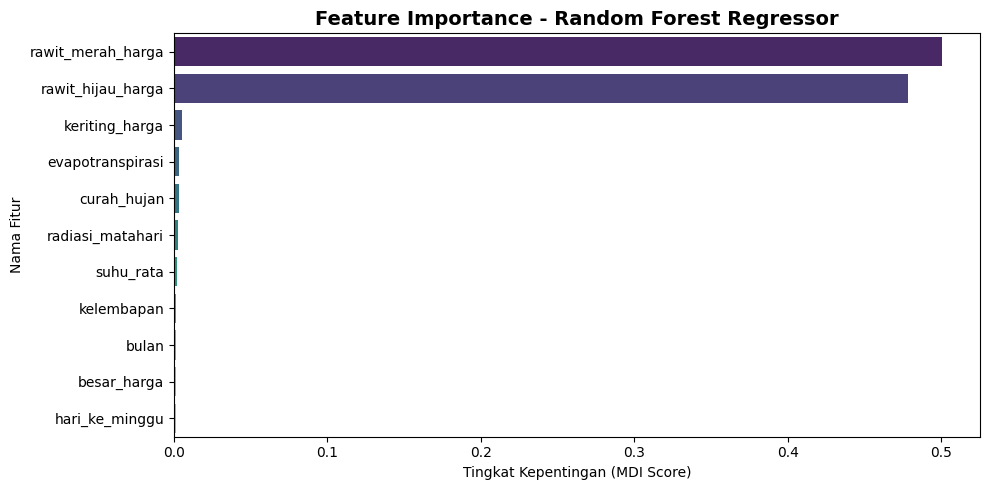

In [ ]:
# 1. Mengambil nilai importance dari model
importances_rf = models["Random Forest Regressor"].feature_importances_

# 2. Membuat DataFrame agar mudah diurutkan dan divisualisasikan
df_rf_importance = pd.DataFrame({
    'Fitur': fitur,
    'Importance': importances_rf
}).sort_values(by='Importance', ascending=False)

# 3. Visualisasi dengan grafik batang
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Fitur', data=df_rf_importance, palette='viridis')
plt.title('Feature Importance - Random Forest Regressor', fontsize=14, fontweight='bold')
plt.xlabel('Tingkat Kepentingan (MDI Score)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

Berdasarkan grafik Feature Importance dari Random Forest Regressor yang Anda lampirkan, terkonfirmasi dengan sangat jelas terjadinya masalah Data Leakage (Kebocoran Data) yang ekstrem.
Dua fitur harga masa lalu, yaitu rawit_hijau_harga (skor MDI ~0.50) dan rawit_merah_harga (skor MDI ~0.47), mendominasi hampir 98% bobot keputusan model dalam memprediksi harga target. Sebaliknya, seluruh fitur cuaca (curah_hujan, suhu_rata, dll.) dan fitur waktu (bulan, hari_ke_minggu) memiliki nilai kepentingan yang mendekati nol.

Model Anda menemukan "jalan pintas" saat fase training. Dalam data deret waktu komoditas pangan pangan, harga hari ini atau minggu lalu memiliki korelasi linier yang sangat kuat dengan harga beberapa minggu ke depan (karena polanya yang berbentuk tangga konstan).

### Soal 2.5: Simpan model final

**Model final yang saya pilih:** `__Linear Regression (Baseline)__`

**Alasan:**

_Linear Regression menjadi model yang paling konsisten dan stabil antara data historis dengan data pengujian (dengan menambahkan beberapa variabel data uji pun Linear Regression tetap konsisten). Pada Grafik Garis merah (Linear Regression) menempel sangat presisi dengan garis aktual hitam_

# Challenge 3 - Prediction
Tujuan: Menggunakan model yang telah dilatih untuk memprediksi data baru yang belum pernah dilihat.

### Soal 3.1: Muat model (jika perlu, jika di-run terpisah dari Challenge 2)

In [ ]:
import os
import joblib

# Membuat folder 'src' di satu tingkat di luar direktori aktif saat ini jika belum ada
os.makedirs('../src', exist_ok=True)
print("Folder ../src siap digunakan!")

Folder ../src siap digunakan!


In [ ]:
# 1. Linear Regression Sebagai Baseline Model
model_final = models["Linear Regression (Baseline)"]

# 2. Tentukan jalur/path lokasi penyimpanan
path_simpan = '../src/model.pkl'

# 3. Eksekusi penyimpanan menggunakan joblib
joblib.dump(model_final, path_simpan)

print(f'Simpan model final ke {path_simpan} BERHASIL!')

Simpan model final ke ../src/model.pkl BERHASIL!


In [ ]:
model_baseline = joblib.load('../src/model.pkl')

### Soal 3.2: Buat data baru untuk diprediksi

In [ ]:
data_baru = pd.DataFrame({
    'besar_harga':[29750, 41100, 51350, 45600, 34700],
    'keriting_harga':[22950, 33150, 39800,37550, 32900],
    'rawit_hijau_harga':[13350, 24250, 28050, 20950, 18850],
    'rawit_merah_harga':[13350,24250, 28050, 20950, 17850],
    'suhu_rata': [22.2, 23.8, 21.6, 23.7, 24.1],
    'curah_hujan': [12.5, 15.2, 24.7, 31.7, 45.0],
    'kelembapan': [82.0, 78.5, 88.0, 88.0, 91.0],
    'radiasi_matahari': [14.2, 18.5, 9.1, 12.61, 15.11],
    'evapotranspirasi': [3.2, 4.1, 2.5, 3.63, 2.14],
    'bulan':[10, 11, 12, 1, 2],
    'hari_ke_minggu': [0, 1, 2, 3, 4]
})

print('Data baru untuk diprediksi:')
print(data_baru)

Data baru untuk diprediksi:
   besar_harga  keriting_harga  rawit_hijau_harga  rawit_merah_harga  \
0        29750           22950              13350              13350   
1        41100           33150              24250              24250   
2        51350           39800              28050              28050   
3        45600           37550              20950              20950   
4        34700           32900              18850              17850   

   suhu_rata  curah_hujan  kelembapan  radiasi_matahari  evapotranspirasi  \
0       22.2         12.5        82.0             14.20              3.20   
1       23.8         15.2        78.5             18.50              4.10   
2       21.6         24.7        88.0              9.10              2.50   
3       23.7         31.7        88.0             12.61              3.63   
4       24.1         45.0        91.0             15.11              2.14   

   bulan  hari_ke_minggu  
0     10               0  
1     11              

### Soal 3.3: Lakukan prediksi dan tampilkan hasil

In [ ]:
hasil_prediksi = model_baseline.predict(data_baru)
print(f'Hasil Prediksi: {hasil_prediksi}')

# Bonus: Tampilkan probability jika model mendukung predict_proba.
# Untuk multiclass, akan ditampilkan probability untuk semua kelas.
try:
    hasil_proba = model.predict_proba(data_baru)

    print('\nPrediction Probability:')
    if hasattr(model, 'classes_'):
        kelas = model.classes_
        for i, proba in enumerate(hasil_proba):
            print(f'Sample {i+1}:')
            for label, probability in zip(kelas, proba):
                print(f'  Class {label}: {probability:.2%}')
    else:
        print(hasil_proba)

except AttributeError:
    print('\nModel ini tidak mendukung predict_proba (misalnya beberapa model regression).')

Hasil Prediksi: [13119.45498713 23902.98369724 27404.61169388 20229.81067231
 19035.03706966]

Model ini tidak mendukung predict_proba (misalnya beberapa model regression).


### Soal 3.4: Muat model kedua

In [ ]:
# 1. Linear Regression Sebagai Baseline Model
model_kedua = models["Random Forest Regressor"]

# 2. Tentukan jalur/path lokasi penyimpanan
path_simpan = '../src/model_kedua.pkl'

# 3. Eksekusi penyimpanan menggunakan joblib
joblib.dump(model_kedua, path_simpan)

print(f'Simpan model final ke {path_simpan} BERHASIL!')

Simpan model final ke ../src/model_kedua.pkl BERHASIL!


### Soal 3.5: Data Baru

In [ ]:
data_baru = pd.DataFrame({
    'besar_harga':[29750, 41100, 51350, 45600, 34700],
    'keriting_harga':[22950, 33150, 39800,37550, 32900],
    'rawit_hijau_harga':[13350, 24250, 28050, 20950, 18850],
    'rawit_merah_harga':[13350,24250, 28050, 20950, 17850],
    'suhu_rata': [22.2, 23.8, 21.6, 23.7, 24.1],
    'curah_hujan': [12.5, 15.2, 24.7, 31.7, 45.0],
    'kelembapan': [82.0, 78.5, 88.0, 88.0, 91.0],
    'radiasi_matahari': [14.2, 18.5, 9.1, 12.61, 15.11],
    'evapotranspirasi': [3.2, 4.1, 2.5, 3.63, 2.14],
    'bulan':[10, 11, 12, 1, 2],
    'hari_ke_minggu': [0, 1, 2, 3, 4]
})

print('Data baru untuk diprediksi:')
print(data_baru)

Data baru untuk diprediksi:
   besar_harga  keriting_harga  rawit_hijau_harga  rawit_merah_harga  \
0        29750           22950              13350              13350   
1        41100           33150              24250              24250   
2        51350           39800              28050              28050   
3        45600           37550              20950              20950   
4        34700           32900              18850              17850   

   suhu_rata  curah_hujan  kelembapan  radiasi_matahari  evapotranspirasi  \
0       22.2         12.5        82.0             14.20              3.20   
1       23.8         15.2        78.5             18.50              4.10   
2       21.6         24.7        88.0              9.10              2.50   
3       23.7         31.7        88.0             12.61              3.63   
4       24.1         45.0        91.0             15.11              2.14   

   bulan  hari_ke_minggu  
0     10               0  
1     11              

### Soal 3.4: Lakukan Prediksi

In [ ]:
hasil_prediksi = model_kedua.predict(data_baru)
print(f'Hasil Prediksi: {hasil_prediksi}')

Hasil Prediksi: [13359.5 26107.  27448.  21285.  19413.5]


/tmp/ipykernel_8728/1713518330.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=df_rf_importance, palette='viridis')


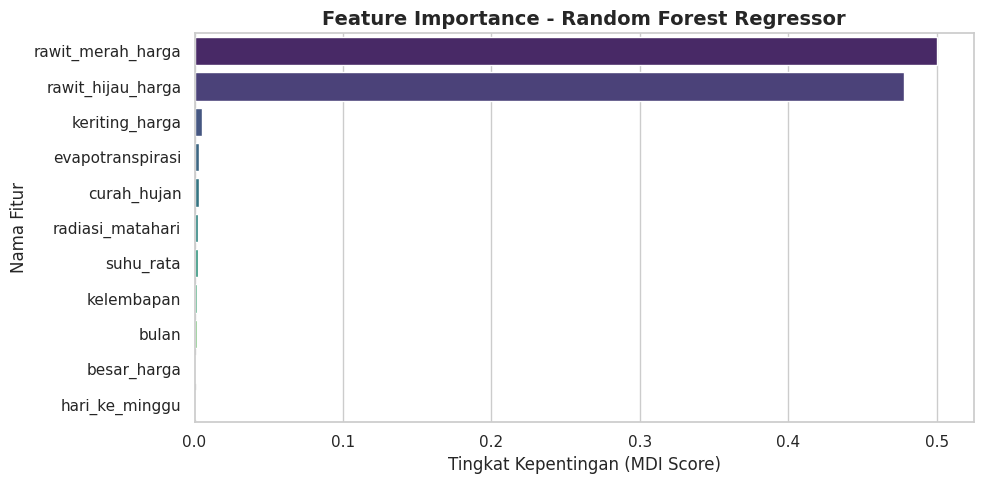

In [ ]:
# 1. Mengambil nilai importance dari model
importances = model_kedua.feature_importances_

# 2. Membuat DataFrame agar mudah diurutkan dan divisualisasikan
df_importances = pd.DataFrame({
    'Fitur': fitur,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Visualisasi dengan grafik batang
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Fitur', data=df_rf_importance, palette='viridis')
plt.title('Feature Importance - Random Forest Regressor', fontsize=14, fontweight='bold')
plt.xlabel('Tingkat Kepentingan (MDI Score)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

# Challenge 4 - Integrasi Gemini API

### Soal 4.1: Setup Gemini API

In [ ]:
!pip install -q google-generativeai

In [ ]:
import os, getpass
GEMINI_API_KEY = ""
#Pilih Model Gemini
GEMINI_MODEL = "gemini-3-flash-preview"

try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY") or ""
except Exception:
    pass
if not GEMINI_API_KEY:
    GEMINI_API_KEY = getpass.getpass("Gemini API key (input disembunyikan): ")


#Apakah API Key tersedia
print("API key tersedia:", bool(GEMINI_API_KEY))
print("Model:", GEMINI_MODEL)

API key tersedia: True
Model: gemini-3-flash-preview


### Soal 4.2: Susun prompt dan minta penjelasan dari Gemini

In [ ]:
import google.genai
# Inisialisasi client Gemini
client = genai.Client(api_key=GEMINI_API_KEY)

prompt = f"""
Anda adalah asisten AI yang bertindak sebagai sistem interpretasi data.
- Transparansi Label AI: Anda wajib menyertakan label di awal atau akhir respons yang menyatakan secara jelas bahwa analisis ini dihasilkan oleh kecerdasan buatan (AI/Machine Learning).
- Disclaimer Akuntabilitas: Anda harus menyertakan penafian (disclaimer) bahwa hasil prediksi dan interpretasi ini bersifat prediktif berdasarkan data historis, tidak menjamin kepastian masa depan, dan keputusan bisnis atau kebijakan strategis harus tetap diverifikasi oleh tenaga ahli/manusia.
- Netralitas Bahasa yang Adil: Gunakan bahasa yang objektif, netral, bebas dari bias, tidak menyudutkan pihak tertentu (seperti petani atau pedagang), dan sampaikan ketidakpastian model (jika ada) secara jujur tanpa melebih-lebihkan akurasi.

[KONTEKS DATA]
Model machine learning telah memprediksi beberapa sampel data baru.
Data baru yang diprediksi:
{data_baru.to_string()}

Hasil prediksi dari model:
{hasil_prediksi}

Penjelasan fitur:
- Kolom1: harga cabai besar
- Kolom2: harga cabai keriting
- Kolom3: harga cabai rawit hijau
- Kolom4: harga cabai rawit merah
- Kolom5: suhu rata-rata
- Kolom6: curah hujan
- Kolom7: kelembapan
- Kolom8: radiasi matahari
- Kolom9: evapotranspirasi
- Kolom10: bulan
- Kolom11: hari ke minggu

1. Jelaskan dengan bahasa yang mudah dipahami (non-teknis) mengapa model memprediksi hasil tersebut berdasarkan nilai-nilai input cuaca dan harga yang ada.
2. Jelaskan implikasi atau interpretasi dari hasil prediksi ini dalam konteks nyata secara objektif.
3. Pastikan elemen Transparansi Label AI dan Disclaimer Akuntabilitas terintegrasi dengan baik dalam output Anda.
"""

try:
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt
    )

    penjelasan = response.text

    print("\n=== Penjelasan dari Gemini ===")
    print(penjelasan)

except Exception as e:
    print(f"Error: {e}")


=== Penjelasan dari Gemini ===
**[ANALISIS INI DIHASILKAN OLEH SISTEM KECERDASAN BUATAN (AI/MACHINE LEARNING)]**

Berikut adalah interpretasi data berdasarkan hasil prediksi model terhadap sampel data yang diberikan:

### 1. Penjelasan Hasil Prediksi (Bahasa Non-Teknis)
Model ini bekerja dengan cara mempelajari pola hubungan antara harga cabai saat ini, kondisi cuaca, dan waktu (bulan). Secara sederhana, berikut adalah alasan mengapa model memberikan hasil prediksi tersebut:

*   **Pengaruh Faktor Cuaca:** Model melihat adanya peningkatan curah hujan yang cukup signifikan dari data ke-0 (12.5 mm) hingga data ke-4 (45.0 mm). Secara historis, curah hujan yang tinggi sering kali dikaitkan dengan tantangan dalam proses panen atau distribusi, yang kemudian tercermin dalam fluktuasi nilai prediksi.
*   **Hubungan dengan Harga Saat Ini:** Nilai prediksi tampak mengikuti tren harga input. Ketika harga cabai (besar, keriting, dan rawit) di pasar sedang tinggi (seperti pada data ke-2), model me

# Challenge 5 - Responsible AI Reflection

### 1. Bias Data
**Pertanyaan:** Apakah dataset yang digunakan berpotensi bias? Apakah data representatif untuk semua kelompok demografis (gender, usia, etnis, lokasi, dll)? Jelaskan konsekuensi jika ada bias.

**Jawaban:**
_Dataset iklim dan harga komoditas cabai Jawa Barat harian periode 2020–2026 ini memiliki batasan dalam hal representativitas dan potensi bias sistematis. Pertama, terdapat data imputation bias yang kuat akibat penggunaan metode forward-fill pada hari libur, ditunjukkan oleh stagnasi harga nominal yang konstan dalam rentang waktu mingguan. Kedua, dataset ini murni bersifat agroklimatologi sektoral sehingga tidak representatif terhadap aspek demografi masyarakat_

---

### 2. Keterbatasan Model
**Pertanyaan:** Dalam kondisi apa model ini bisa memberikan prediksi yang salah atau menyesatkan? Apakah ada edge cases atau input yang tidak valid?

**Jawaban:**
_Model regresi prediksi harga cabai rawit memiliki risiko menyesatkan apabila dihadapkan pada faktor eksternal non-stastistik seperti intervensi kebijakan operasi pasar pemerintah, kepanikan konsumen (panic buying), kerusakan lahan akibat cuaca ekstrem mendadak. Edge cases utama dari model ini terletak pada periode anomali hari raya keagamaan saat aktivitas pasar logistik lumpuh total.

---

### 3. Transparansi AI Generatif
**Pertanyaan:** Penjelasan di Challenge 4 dihasilkan oleh AI (Gemini). Apakah pengguna akhir PERLU TAHU bahwa penjelasan ini dari AI? Apa risikonya jika tidak transparansi?

**Jawaban:**
_Pengguna akhir PERLU TAHU bahwa penjelasan tersebut dai AI, Risiko jika tidak ada transparansi antara lain Halusinasi informasi, bisa saja narasi terdengar masuk akal walapun ada kesalahan, Kekeliruan pengambilan keputusan, kehilangan kepercayaan dan ketiadaan akuntabilitas Hukum  _

---

### 4. Dampak Sosial
**Pertanyaan:** Jika model ini digunakan dalam skala besar/nyata (misalnya di aplikasi mobile, rumah sakit, atau perusahaan), dampak apa yang mungkin timbul (positif & negatif)? Siapa saja yang bisa terpengaruh?

**Jawaban:**
_Dampak positif, adanya Transparansi harga di rantai pasok, perencanaan Tanam pertanian, stabilisasi inflasi daerah (misal, redistribusi stok dari daerah surplus ke daerah defisit)_

_Dampak Negatif : Eksploitasi oleh tengkulak, pihak yang memiliki modal besar dapat menggunakan app tersebut untuk menimbun barang. Adanya ketergantungan berlebihan, petani bisa kehilangan intuisi tradisional dalam membaca alam. Efek Domino jika AI mengalami halusinasi (misal, salah memprediksi harga akan anjlok parah padahal sebenarnya stabil)_

_Pihak-pihak yang terpengaruh antara lain: Petani Cabai, Pedagang pasar & distributor, konsumen akhir(masyarakat), dan Pemerintah daerah (Dinas Ketahanan Pangan)_

---

### 5. Rekomendasi Responsible AI
**Pertanyaan:** Apa langkah/strategi yang bisa diambil untuk membuat sistem ini lebih bertanggung jawab (responsible AI)? Pikir tentang: transparency, fairness, accountability, security, dll.

**Jawaban:**
_Respon wajib diawali dan diakhiri dengan pernyataan jelas bahwa teks narasi di produksi oleh AI, membedakan dengan jelas angka mutlak dan hasil kalkulasi model ML dengan interpretasi AI, pencantuman Sumber Data rujukan._

_Disclaimer menyatakan bahwa narasi ini berupa prediksi, menyediakan jalur verifikasi (misal cek kembali di kanal resmi pemerintah). Perlindungan data pribada, AI tidak boleh meminta, merekam, atau menyebarkan data sensitif pengguna (misal koordinat persis sawah/ladang)_

_Penjelasan menggunakan istilah universal yang mudah dipahami oleh semua lapisan masyarakat. AI tidak memberikan rekomendasi sepihak yang hanya menguntungkan pihak-pihak tertentu (misal tengkulak untuk menimbun hasil panen)_

---